# Integrate (batch correct) single cell datasets with scanpy and harmony

This notebook demonstrates integration and batch correction of single-cell RNA-seq datasets using Scanpy and harmony-tools. Below, each section is preceded by a brief explanation of its function.

## load required packages
Imports Python libraries for single-cell analysis, plotting, and data handling.

In [1]:
import scanpy as sc
from pathlib import Path
import anndata as ad
import re
import pandas as pd
import matplotlib.pyplot as plt
import os
import math
from anndata import AnnData
from typing import Optional, Dict
import grthub_tools as gt
import squidpy as sq


/data/homezvol1/kstachel/.conda/envs/squidpy/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/data/homezvol1/kstachel/.conda/envs/squidpy/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)
/data/homezvol1/kstachel/.conda/envs/squidpy/lib/python3.12/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/data/homez

## set scanpy default display settings 
Configures verbosity and figure parameters for consistent plotting.

In [2]:
sc.settings.verbosity = 1 # verbosity: errors (0), warnings (1), info (2), hints (3)
sc.settings.set_figure_params(vector_friendly=False, dpi=100, fontsize=10, dpi_save=300, figsize=(5,4), format='png')

Reads the processed single-cell data for analysis.

In [7]:
combined_adata_path = "../output/scanpy/all_harmony_integrated.h5ad"
batch_variable = "batch"
groupby_var = "condition"
group1_value = "heat_stress"
group2_value = "control"


In [8]:
slug = re.search(r'(.*)_harmony_integrated.h5ad', os.path.basename(combined_adata_path)).group(1)

In [9]:
combined_adata = sc.read_h5ad(combined_adata_path)

# use slighly lower resolution to capture likely # of cell types in mouse brain (0.5 -> 0.4)
Performs clustering on the integrated data using the Leiden algorithm at a specified resolution.

In [10]:
# neighbors were already computed using harmony
HARMONY_CLUSTERS_KEY = "leiden_harmony"
sc.tl.leiden(combined_adata, key_added=HARMONY_CLUSTERS_KEY, resolution=0.4)

/tmp/ipykernel_3844908/3193434584.py:3: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(combined_adata, key_added=HARMONY_CLUSTERS_KEY, resolution=0.4)


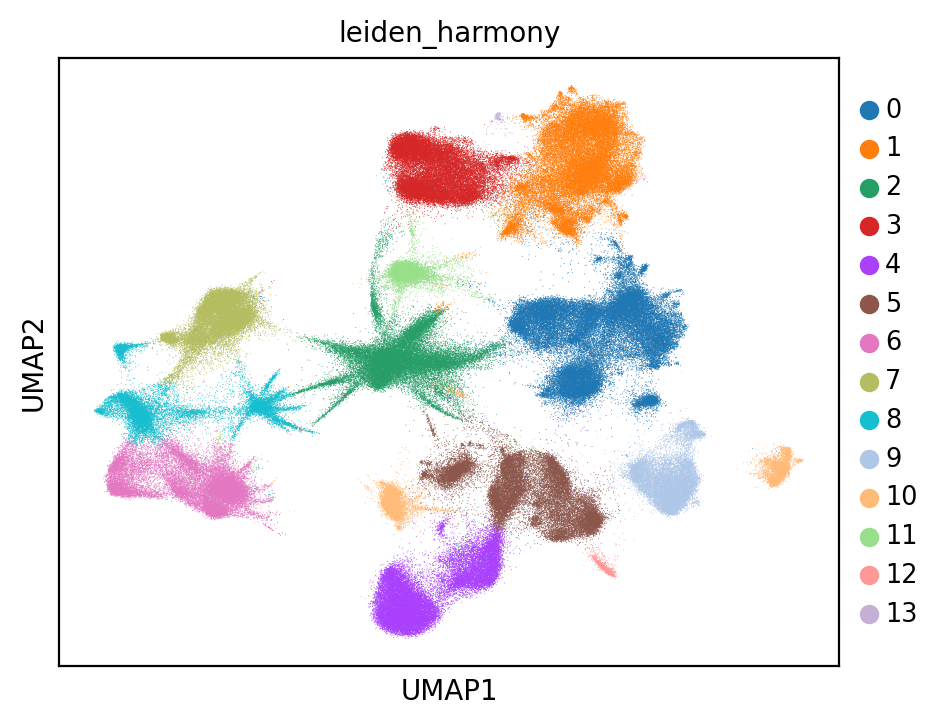

In [14]:
sc.pl.umap(combined_adata, color=[HARMONY_CLUSTERS_KEY], wspace=0.4, save=f"_{slug}_{HARMONY_CLUSTERS_KEY}.png")

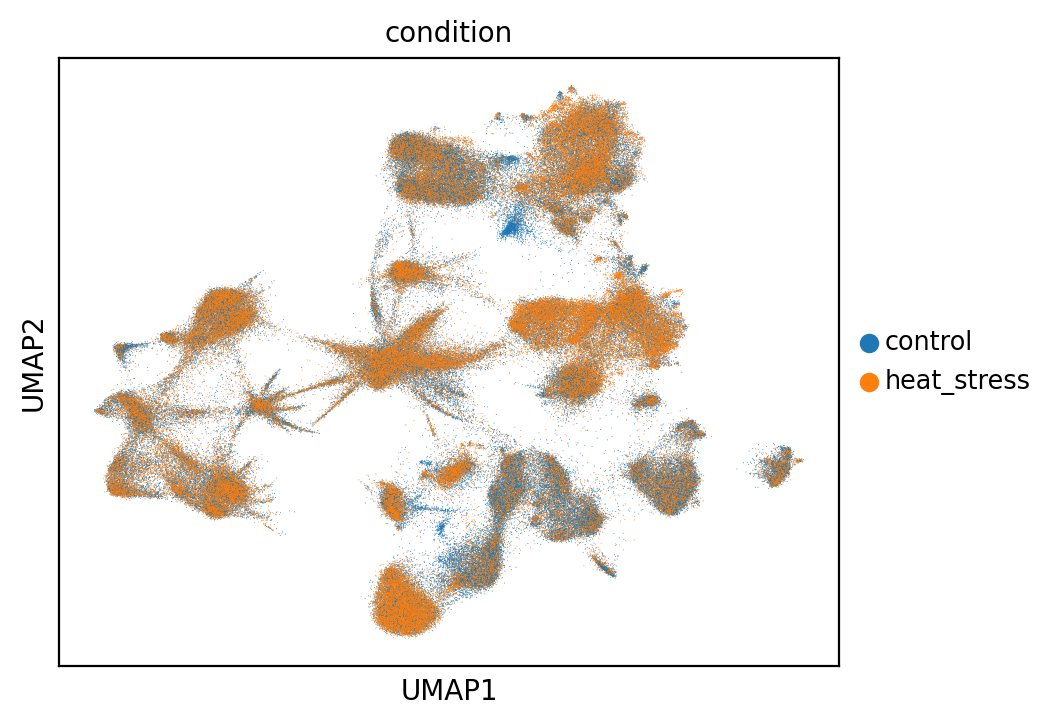

In [15]:
sc.pl.umap(combined_adata, color=[groupby_var], wspace=0.4, save=f"_{slug}_{groupby_var}.png")

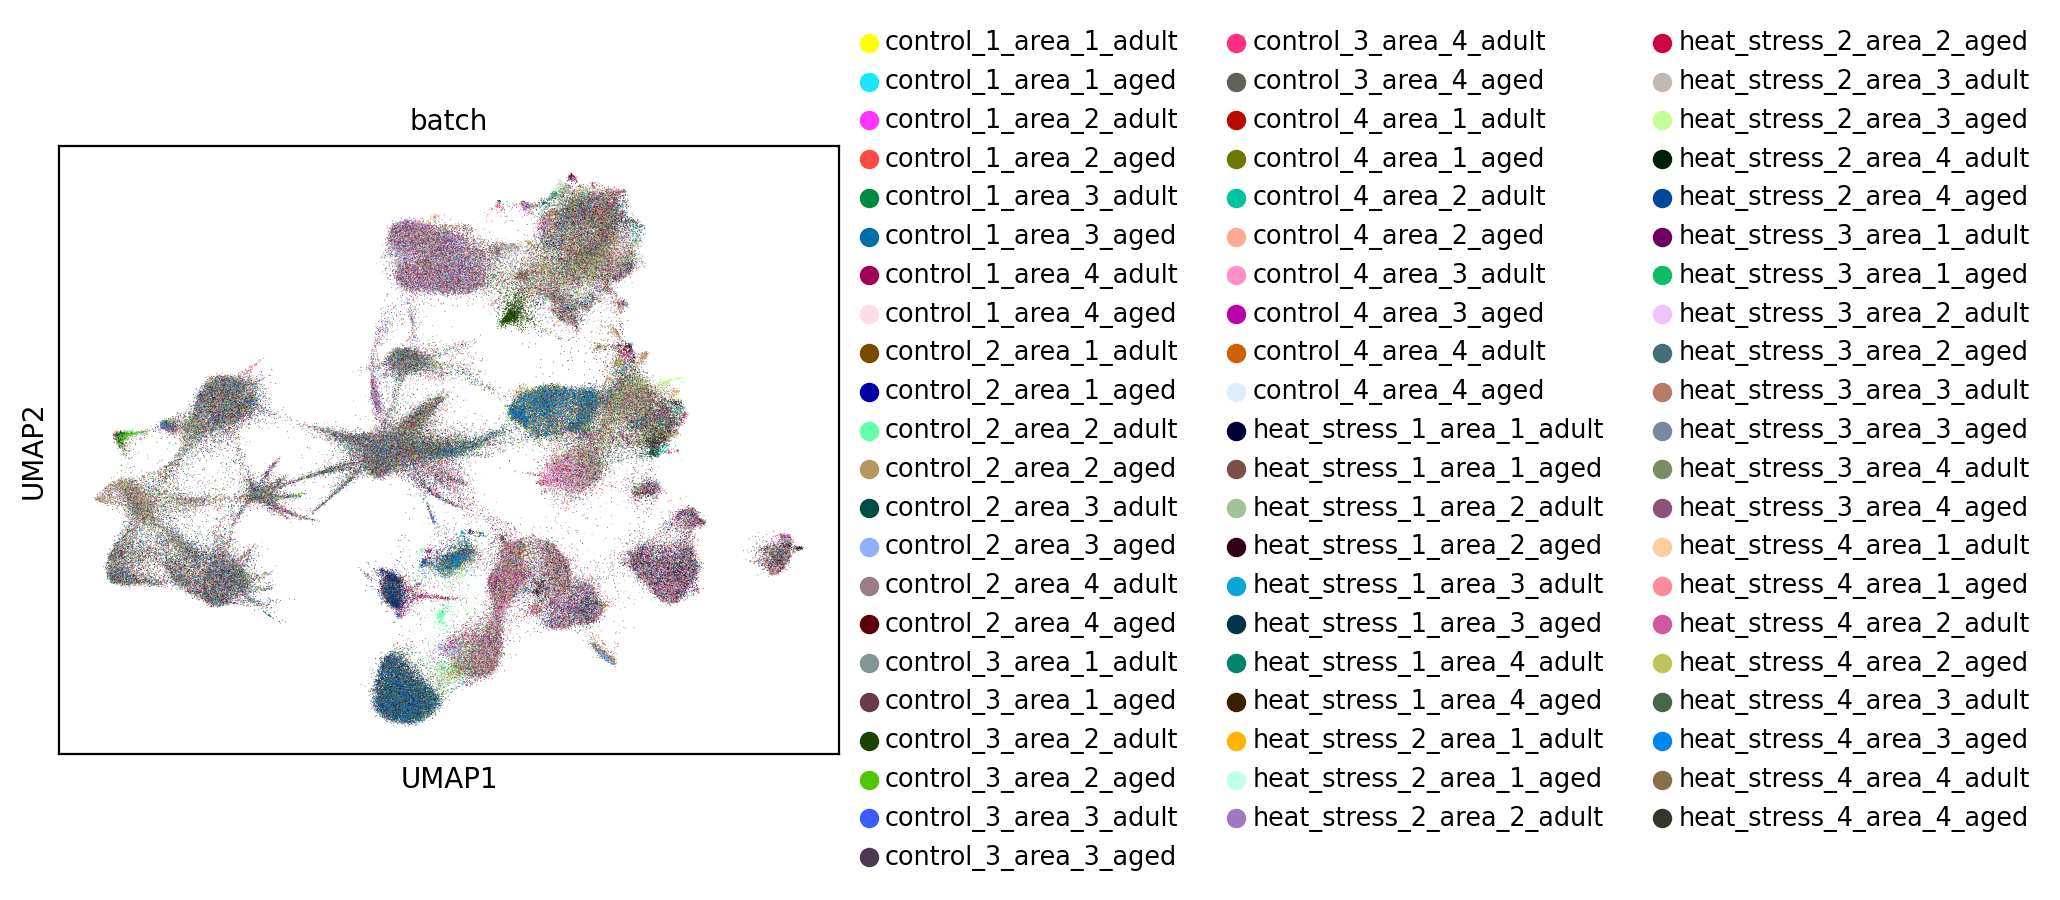

In [16]:
sc.pl.umap(combined_adata, color=["batch"], wspace=0.4, save=f"_{slug}_{"batch"}.png")

In [35]:
group_columns = ["leiden_harmony", "age", "condition", "area", "sample_id"]

In [46]:
all_metadata = combined_adata.obs[["cell_id"] + group_columns]
all_metadata.drop_duplicates(subset=['cell_id'])

all_metadata.to_excel(f"{slug}_adult_metadata.xlsx")

/data/homezvol1/kstachel/.conda/envs/squidpy/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/data/homezvol1/kstachel/.conda/envs/squidpy/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


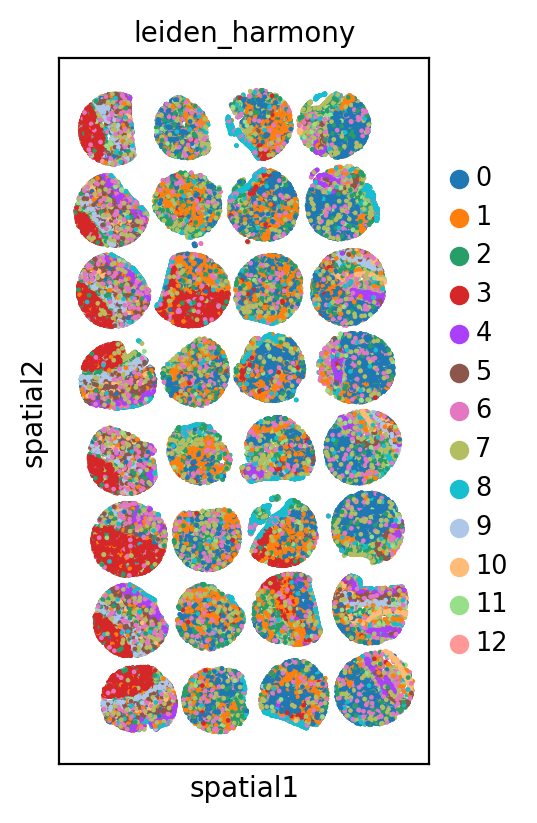

In [45]:
os.makedirs("aged", exist_ok=True)
for column in group_columns:
    exported_clusters = combined_adata[combined_adata.obs['age'] == 'aged', :].obs[["cell_id", column]]
    exported_clusters.drop_duplicates(subset=['cell_id'])
    exported_clusters.columns = ["cell_id", "group"]
    exported_clusters.to_csv(f"aged/{slug}_aged_{column}_clusters.csv")

sq.pl.spatial_scatter(
    combined_adata[combined_adata.obs['age'] == 'aged', :],
    library_id="spatial",
    color="leiden_harmony",
    shape=None,
    size=2,
    save = f"aged_leiden_harmony_spatial_scatter_{slug}.png",
)

/data/homezvol1/kstachel/.conda/envs/squidpy/lib/python3.12/site-packages/squidpy/pl/_color_utils.py:28: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  target.uns[color_key] = source.uns[color_key]
/data/homezvol1/kstachel/.conda/envs/squidpy/lib/python3.12/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


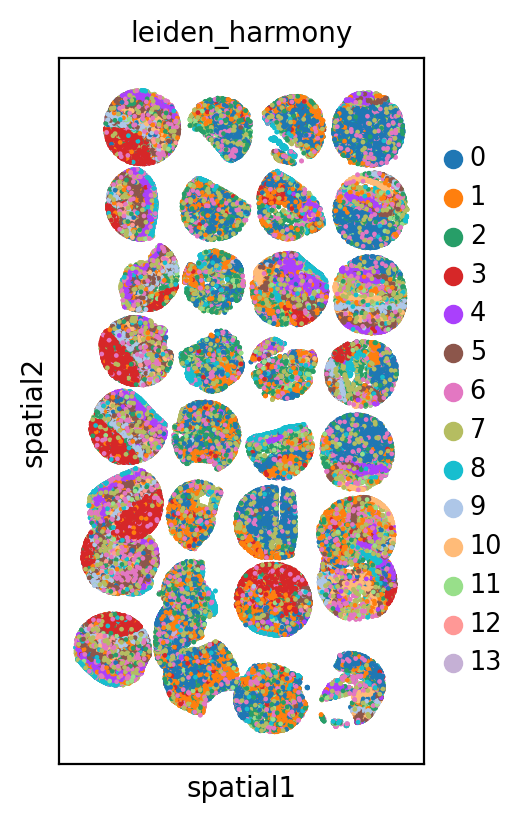

In [47]:
os.makedirs("adult", exist_ok=True)
for column in group_columns:
    exported_clusters = combined_adata[combined_adata.obs['age'] == 'adult', :].obs[["cell_id", column]]
    exported_clusters.drop_duplicates(subset=['cell_id'])
    exported_clusters.columns = ["cell_id", "group"]
    exported_clusters.to_csv(f"adult/{slug}_adult_{column}_clusters.csv")

sq.pl.spatial_scatter(
    combined_adata[combined_adata.obs['age'] == 'adult', :],
    library_id="spatial",
    color="leiden_harmony",
    shape=None,
    size=2,
    save = f"adult_leiden_harmony_spatial_scatter_{slug}.png",
)

### Visualization with batch correction (harmony)

Now, let us try using the harmony latent space to generate the same UMAP plots to see if harmony successfully accounts for batch effects in the data.

In [23]:
# use harmony latent space for UMAP generation
harmony_LATENT_KEY = "X_pca_harmony"
sc.pp.neighbors(combined_adata, use_rep=harmony_LATENT_KEY)
sc.tl.umap(combined_adata, min_dist=0.3)

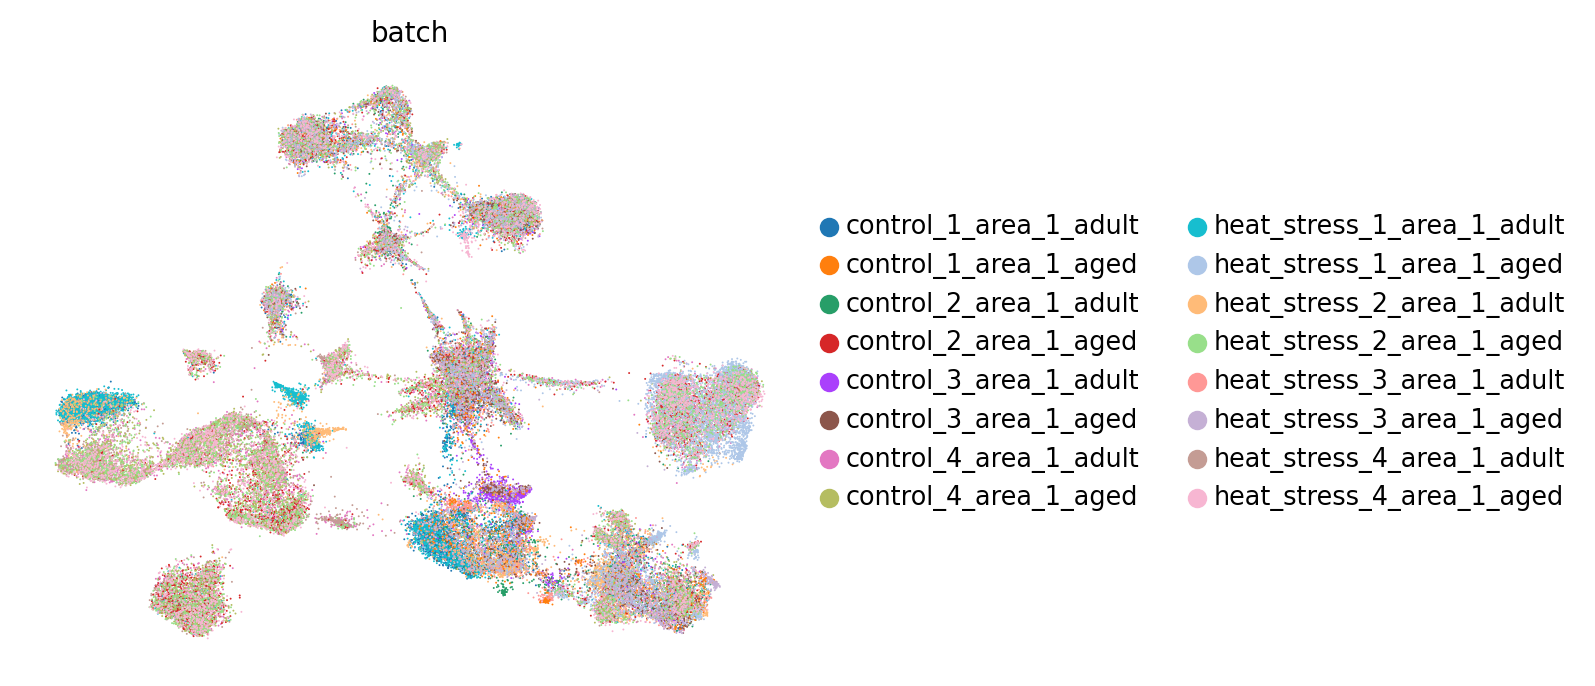

In [ ]:
sc.pl.umap(
    combined_adata,
    color=[batch_variable],
    frameon=False,
)


We can see that harmony was able to correct for nuisance variation due to nuclei/whole cell, age group, and donor, while maintaining separation of cell types.

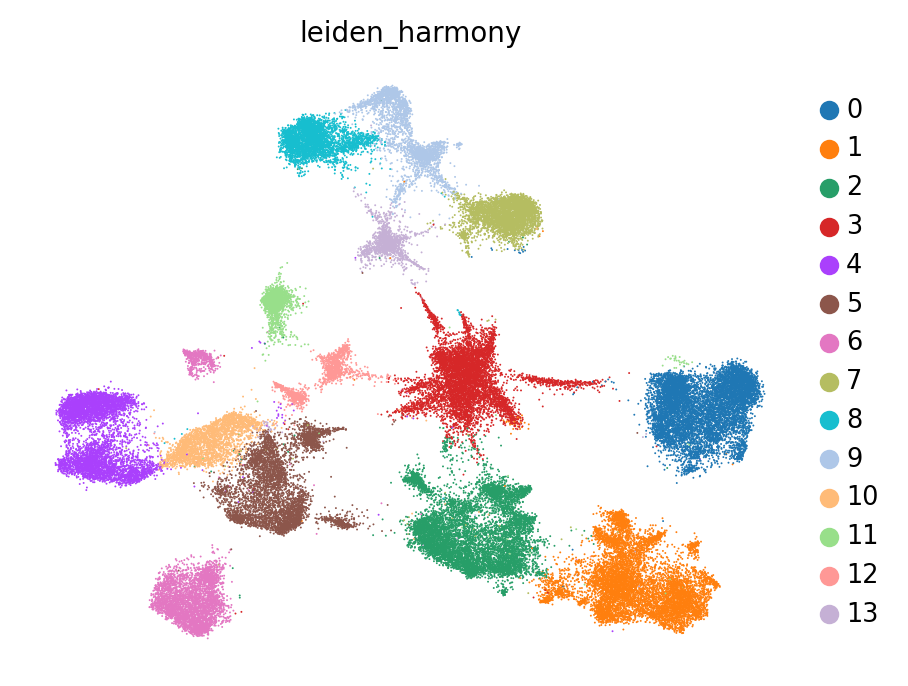

In [27]:
sc.pl.umap(
    combined_adata,
    color=[HARMONY_CLUSTERS_KEY],
    frameon=False,
)

## Find marker genes for our integrated data using scanpy `rank_genes_groups`

In [29]:

# Find marker genes for each cluster
sc.tl.rank_genes_groups(combined_adata, HARMONY_CLUSTERS_KEY, method='wilcoxon')

#  Stacked Bar Plot of cluster membership by batch

## View the distribution of batches across clusters to get a sense of any sample-specific cell types/states

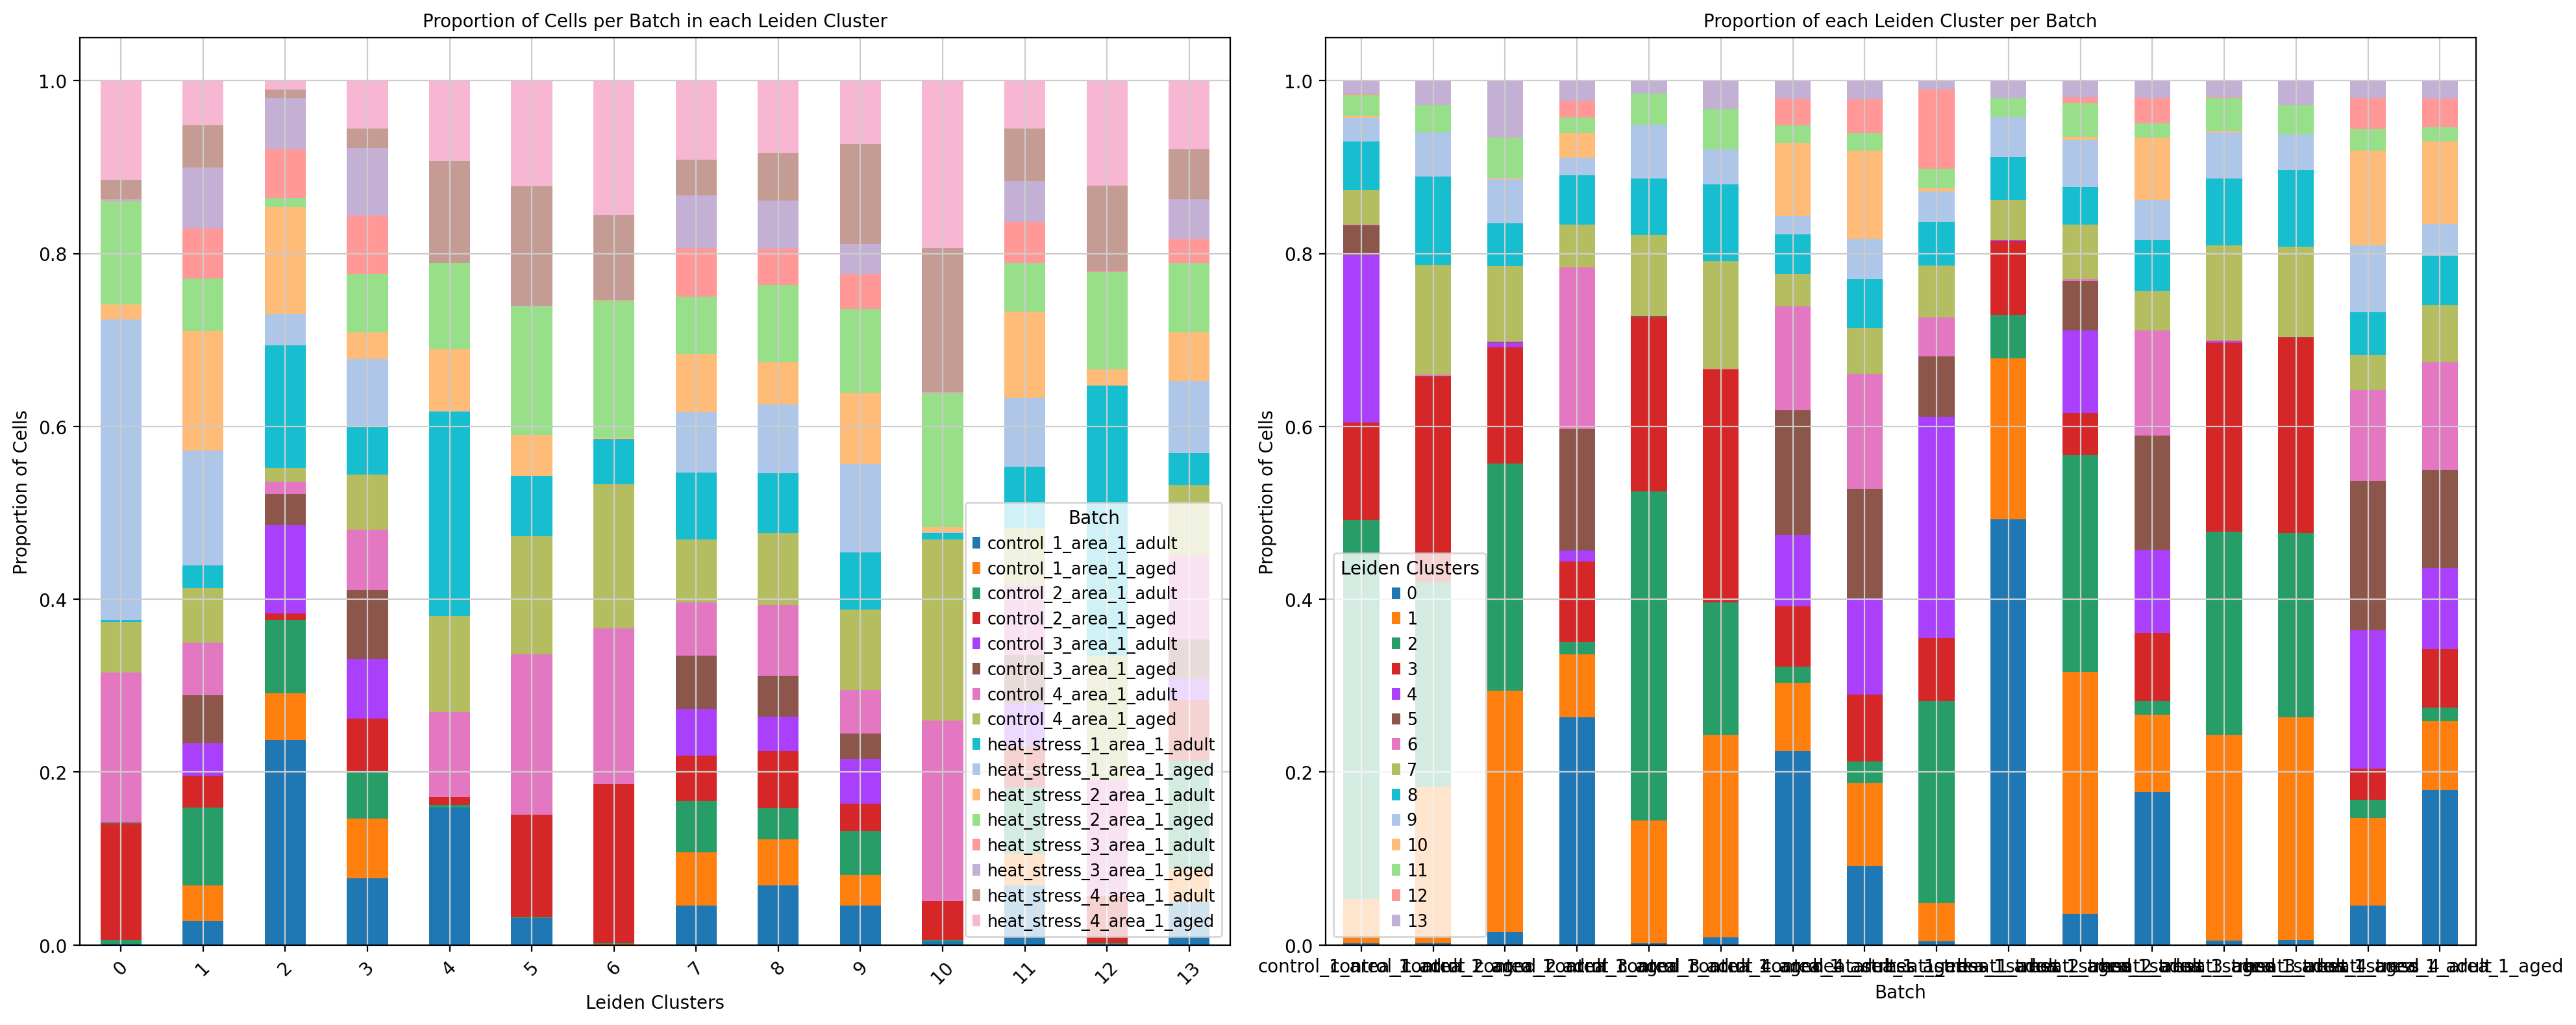

In [30]:
# Create the two cross-tabulation dataframes
crosstab_df_1 = pd.crosstab(combined_adata.obs[HARMONY_CLUSTERS_KEY], combined_adata.obs['batch'], normalize='index')
crosstab_df_2 = pd.crosstab(combined_adata.obs['batch'], combined_adata.obs[HARMONY_CLUSTERS_KEY], normalize='index')

# Set up the subplot figure and axes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8), sharey=False) # Use sharey=True if you want the same y-axis scale

# Plot the first cross-tabulation on the first axis
crosstab_df_1.plot(kind='bar', stacked=True, ax=ax1)
ax1.set_title('Proportion of Cells per Batch in each Leiden Cluster')
ax1.set_xlabel('Leiden Clusters')
ax1.set_ylabel('Proportion of Cells')
ax1.legend(title='Batch')
ax1.tick_params(axis='x', rotation=45)

# Plot the second cross-tabulation on the second axis
crosstab_df_2.plot(kind='bar', stacked=True, ax=ax2)
ax2.set_title('Proportion of each Leiden Cluster per Batch')
ax2.set_xlabel('Batch')
ax2.set_ylabel('Proportion of Cells')
ax2.legend(title='Leiden Clusters')
ax2.tick_params(axis='x', rotation=0)

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

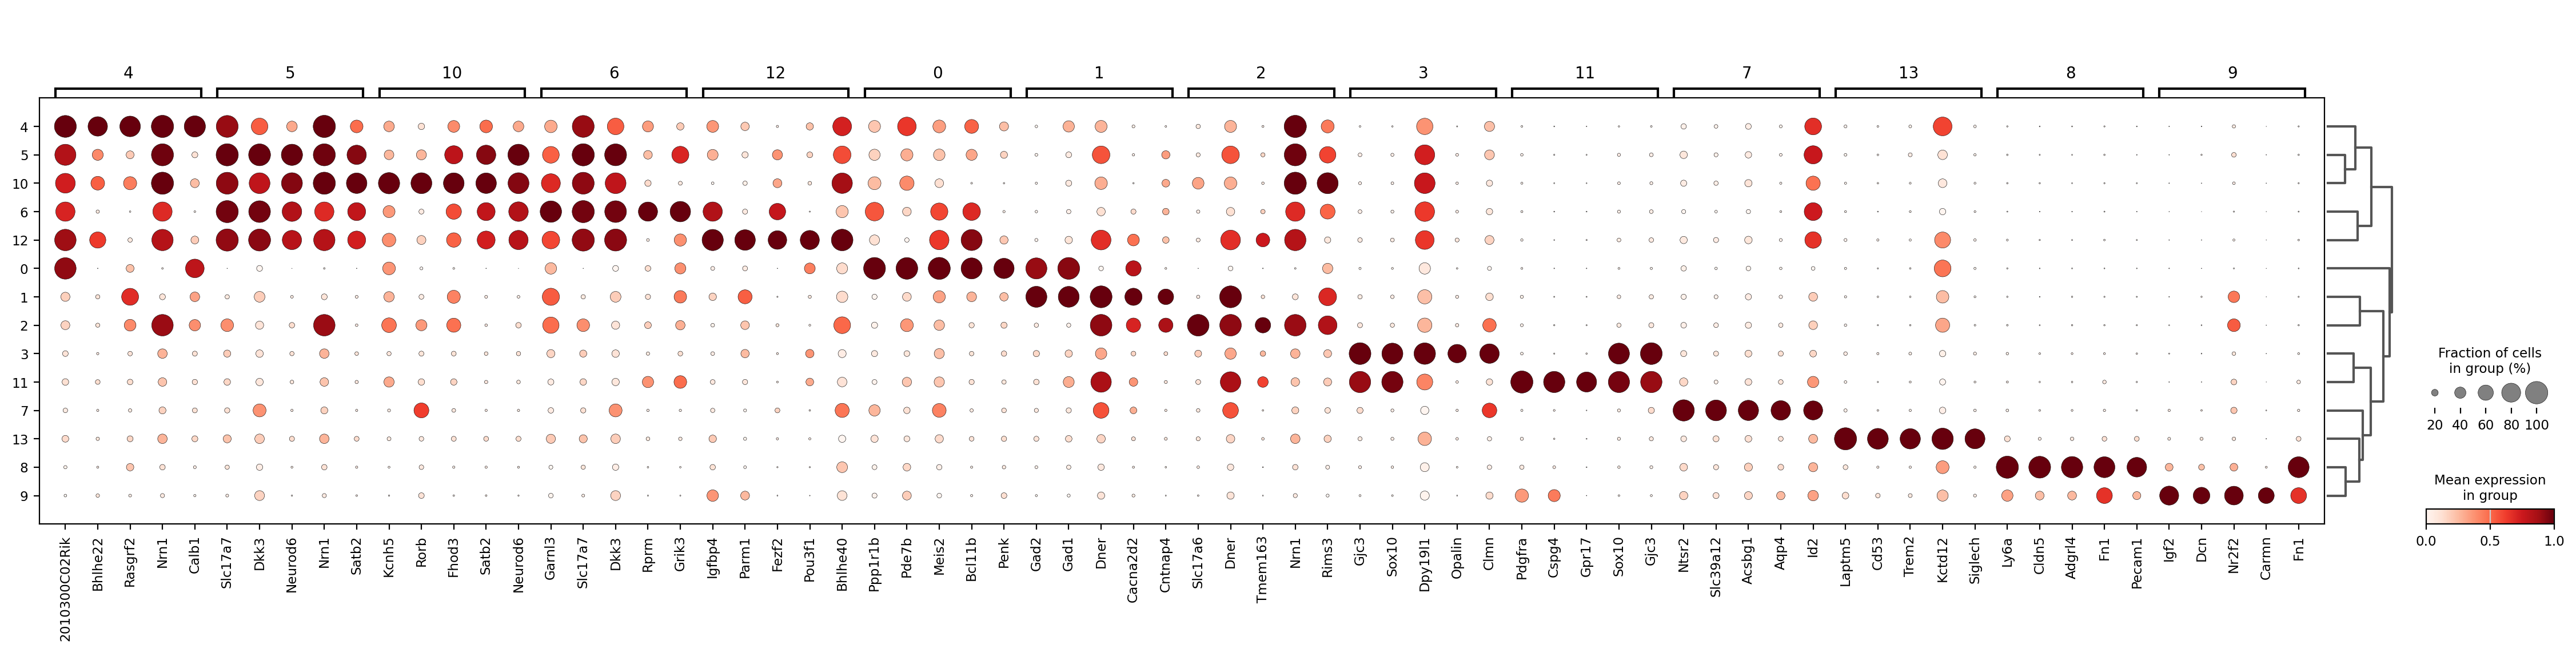

In [31]:
sc.pl.rank_genes_groups_dotplot(
    combined_adata, groupby=HARMONY_CLUSTERS_KEY, standard_scale="var", n_genes=5
)

In [32]:
# Create a copy to avoid modifying the original data
annotated_table = crosstab_df_1.copy()

# Add a 'Total' column for clarity
annotated_table['Total'] = annotated_table.sum(axis=1)

# Calculate and format percentages for each cell
for col in crosstab_df_1.columns:
    # Use f-strings to combine the count and the formatted percentage
    annotated_table[col] = crosstab_df_1.apply(
        lambda row: f"{row[col] / row.sum() * 100:.1f}%",
        axis=1
    )

annotated_table

batch,control_1_area_1_adult,control_1_area_1_aged,control_2_area_1_adult,control_2_area_1_aged,control_3_area_1_adult,control_3_area_1_aged,control_4_area_1_adult,control_4_area_1_aged,heat_stress_1_area_1_adult,heat_stress_1_area_1_aged,heat_stress_2_area_1_adult,heat_stress_2_area_1_aged,heat_stress_3_area_1_adult,heat_stress_3_area_1_aged,heat_stress_4_area_1_adult,heat_stress_4_area_1_aged,Total
leiden_harmony,,,,,,,,,,,,,,,,,
0,0.1%,0.0%,0.5%,13.3%,0.0%,0.2%,17.3%,5.9%,0.2%,34.8%,1.8%,11.9%,0.1%,0.2%,2.2%,11.5%,1.0
1,2.8%,4.1%,9.0%,3.7%,3.8%,5.5%,6.1%,6.3%,2.7%,13.2%,13.9%,6.1%,5.7%,7.1%,4.9%,5.2%,1.0
2,23.7%,5.4%,8.5%,0.7%,10.3%,3.6%,1.4%,1.6%,14.2%,3.6%,12.4%,1.0%,5.7%,5.9%,1.0%,1.0%,1.0
3,7.7%,6.9%,5.5%,6.1%,6.9%,8.0%,6.9%,6.4%,5.6%,7.8%,3.1%,6.8%,6.7%,7.9%,2.2%,5.5%,1.0
4,15.9%,0.0%,0.3%,0.9%,0.0%,0.0%,9.9%,11.1%,23.6%,0.1%,7.2%,10.0%,0.0%,0.0%,11.8%,9.3%,1.0
5,3.1%,0.0%,0.0%,11.9%,0.0%,0.0%,18.6%,13.6%,7.0%,0.0%,4.7%,14.9%,0.0%,0.0%,13.8%,12.2%,1.0
6,0.1%,0.0%,0.0%,18.4%,0.0%,0.0%,18.0%,16.7%,5.2%,0.0%,0.2%,15.9%,0.0%,0.0%,9.8%,15.5%,1.0
7,4.6%,6.1%,5.9%,5.3%,5.3%,6.2%,6.2%,7.3%,7.7%,7.0%,6.7%,6.7%,5.6%,6.1%,4.1%,9.1%,1.0
8,6.9%,5.3%,3.6%,6.6%,4.0%,4.7%,8.2%,8.3%,6.9%,8.0%,4.9%,9.0%,4.2%,5.5%,5.5%,8.4%,1.0


# Export processed anndata object with harmony embeddings and cluster labels

In [ ]:
combined_adata.write_h5ad(f"output/scanpy/{slug}_harmony_integrated_processed.h5ad")

In [ ]:
# Access the marker genes
marker_genes_df = sc.get.rank_genes_groups_df(combined_adata, group=None)
marker_genes_df.to_csv(f"results/{slug}_marker_genes_per_cluster.csv")

In [ ]:
# compare 'treated' vs 'control' within each 'leiden' cluster
res = gt.rank_genes_groups_within_clusters(
    combined_adata,
    groupby=groupby_var,
    cluster_key="leiden_harmony",
    group1=group1_value,
    group2=group2_value,
    key_prefix="rgg_condition_vs_control"
)


/tmp/ipykernel_2683015/4253405084.py:60: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  clusters = pd.Categorical(adata.obs[cluster_key]).categories if pd.api.types.is_categorical_dtype(adata.obs[cluster_key]) else np.unique(adata.obs[cluster_key].astype(str))


In [ ]:
combined_adata.obs.value_counts(subset=[groupby_var, "leiden_harmony"])

In [ ]:
out_path = f"results/{slug}_{groupby_var}_ranked_genes_per_cluster.xlsx"
with pd.ExcelWriter(out_path, engine="openpyxl") as writer:
    for sheet_name, df in res.items():
        # Excel sheet names are max 31 chars; sanitize if needed
        safe_name = str(sheet_name)[:31]
        df.to_excel(writer, sheet_name=safe_name, index=False)
# file closed & written

dict_keys(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13'])